# استيراد المكتبات واستكشاف البيانات

In [9]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy import stats

warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.bbox'] = 'tight'

if not os.path.exists('charts'):
    os.makedirs('charts')

df = pd.read_csv('owid-energy-data.csv')

In [10]:
print("Shape:", df.shape)
print("Years:", df['year'].min(), "to", df['year'].max())
print(df.dtypes.value_counts())

display(df.head())
display(df.tail())

cols = [
    'country', 'year', 'iso_code', 'population', 'gdp',
    'primary_energy_consumption', 'electricity_generation',
    'greenhouse_gas_emissions', 'carbon_intensity_elec',
    'renewables_share_elec', 'low_carbon_share_elec', 'coal_share_elec'
]

Shape: (23377, 130)
Years: 1900 to 2025
float64    127
object       2
int64        1
Name: count, dtype: int64


,country,year,iso_code,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,...,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN


,country,year,iso_code,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,...,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
23372,Zimbabwe,2020,ZWE,15526887.0,2.317871e+10,NaN,0.0,0.0,0.0,6.440441,...,0.298063,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN
23373,Zimbabwe,2021,ZWE,15797220.0,2.514009e+10,NaN,0.0,0.0,0.0,6.963251,...,0.233372,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN
23374,Zimbabwe,2022,ZWE,16069061.0,2.590159e+10,NaN,0.0,0.0,0.0,6.845453,...,0.335570,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN
23375,Zimbabwe,2023,ZWE,16340829.0,NaN,NaN,0.0,0.0,0.0,7.343568,...,0.300300,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN
23376,Zimbabwe,2024,ZWE,16634366.0,NaN,NaN,0.0,0.0,0.0,7.213981,...,0.389864,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,NaN


In [11]:
summary = df[cols].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]
display(summary)

,count,mean,std,min,50%,max
year,23377.0,1.976239e+03,3.533109e+01,1900.0,1.985000e+03,2.025000e+03
population,18894.0,1.058587e+08,4.720948e+08,1776.0,6.951653e+06,8.231613e+09
gdp,11780.0,4.257565e+11,3.507870e+12,164206000.0,4.357680e+10,1.301126e+14
primary_energy_consumption,13255.0,4.254769e+03,1.489751e+04,0.0,9.118718e+01,1.767371e+05
electricity_generation,7913.0,8.039990e+02,2.687185e+03,0.0,2.186000e+01,3.177235e+04
greenhouse_gas_emissions,6028.0,3.399947e+02,1.384213e+03,0.0,3.330000e+00,1.457048e+04
carbon_intensity_elec,6332.0,4.771739e+02,2.414455e+02,0.0,5.238100e+02,1.306720e+03
renewables_share_elec,7872.0,2.998585e+01,3.060305e+01,0.0,1.861431e+01,1.000000e+02
low_carbon_share_elec,7872.0,3.561350e+01,3.150037e+01,0.0,2.961429e+01,1.000000e+02
coal_share_elec,7142.0,1.709644e+01,2.400196e+01,0.0,1.713080e+00,1.000000e+02


# فحص جودة البيانات

In [12]:
# Missing values
print(df[cols].isnull().sum())

# Duplicates & checks
print("Duplicates:", df.duplicated().sum())
print("Country-year duplicates:", df.duplicated(subset=['country', 'year']).sum())
print("Years > 2026:", (df['year'] > 2026).sum())

# Simple IQR outliers check
sov_df = df[df['iso_code'].notnull()]
target_cols = ['primary_energy_consumption', 'electricity_generation', 'greenhouse_gas_emissions', 'carbon_intensity_elec', 'coal_share_elec']

for col in target_cols:
    s = sov_df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {outliers} outliers")

country                           0
year                              0
iso_code                       6112
population                     4483
gdp                           11597
primary_energy_consumption    10122
electricity_generation        15464
greenhouse_gas_emissions      17349
carbon_intensity_elec         17045
renewables_share_elec         15505
low_carbon_share_elec         15505
coal_share_elec               16235
dtype: int64
Duplicates: 0
Country-year duplicates: 0
Years > 2026: 0
primary_energy_consumption: 1414 outliers
electricity_generation: 933 outliers
greenhouse_gas_emissions: 810 outliers
carbon_intensity_elec: 25 outliers
coal_share_elec: 648 outliers


# Data Cleaning

## الفلترة الأساسية وتحديد الأعمدة والسنوات (2000-2023)

In [13]:
df_clean = df.copy()
df_clean['entity_type'] = np.where(df_clean['iso_code'].notna(), 'Country', 'Aggregate')

# Keep world data separate
df_world = df_clean[df_clean['country'] == 'World'].copy()

# Filter countries and years (2000-2023)
df_clean = df_clean[(df_clean['entity_type'] == 'Country') & (df_clean['year'].between(2000, 2023))].copy()

cols = [
    'country', 'iso_code', 'year', 'population', 'gdp',
    'primary_energy_consumption', 'energy_per_capita', 'energy_per_gdp',
    'electricity_generation', 'electricity_demand', 'per_capita_electricity',
    'greenhouse_gas_emissions', 'carbon_intensity_elec',
    'renewables_share_elec', 'renewables_share_energy',
    'low_carbon_share_elec', 'low_carbon_share_energy',
    'coal_share_elec', 'coal_share_energy',
    'gas_share_elec', 'oil_share_elec', 'fossil_share_elec',
    'solar_share_elec', 'wind_share_elec', 'hydro_share_elec', 'nuclear_share_elec'
]
df_clean = df_clean[cols].sort_values(['country', 'year']).reset_index(drop=True)

print("Shape after initial filter:", df_clean.shape)

Shape after initial filter: (5260, 26)


## استبعاد الدول الضعيفة ومعالجة الفجوات

In [14]:
# Drop countries with less than 5 years of data
valid_countries = df_clean.groupby('country').filter(
    lambda g: g['electricity_generation'].notna().sum() >= 5 or g['primary_energy_consumption'].notna().sum() >= 5
)['country'].unique()
df_clean = df_clean[df_clean['country'].isin(valid_countries)].copy()

# Interpolate short gaps inside series
interp_cols = [c for c in cols if c not in ['country', 'iso_code', 'year']]
for col in interp_cols:
    df_clean[col] = df_clean.groupby('country')[col].transform(
        lambda s: s.interpolate(method='linear', limit=2, limit_area='inside')
    )

print("Shape after interpolation:", df_clean.shape)

Shape after interpolation: (5236, 26)


## معالجة الأصفار، عمل الـ Bins، وحفظ الملف النهائي

In [17]:
# Fill 0 for missing share values where generation exists
share_cols = ['nuclear_share_elec', 'solar_share_elec', 'wind_share_elec', 'hydro_share_elec', 'coal_share_elec', 'gas_share_elec', 'oil_share_elec']
for col in share_cols:
    mask = df_clean['electricity_generation'].notna() & df_clean[col].isna()
    df_clean.loc[mask, col] = 0.0

# Create analysis bins
df_clean['coal_dependency_group'] = pd.cut(
    df_clean['coal_share_elec'], bins=[-0.01, 5, 30, 100.01],
    labels=['Low Coal (<5%)', 'Moderate Coal (5-30%)', 'High Coal (>30%)']
)
df_clean['clean_energy_group'] = pd.cut(
    df_clean['low_carbon_share_elec'], bins=[-0.01, 20, 50, 100.01],
    labels=['Low Clean (<20%)', 'Moderate Clean (20-50%)', 'Clean Leader (>50%)']
)

df_clean.to_csv('cleaned_data.csv', index=False)
print("Saved final cleaned data:", df_clean.shape)
display(df_clean.head(3))

Saved final cleaned data: (5236, 28)


,country,iso_code,year,population,gdp,primary_energy_consumption,energy_per_capita,energy_per_gdp,electricity_generation,electricity_demand,...,coal_share_energy,gas_share_elec,oil_share_elec,fossil_share_elec,solar_share_elec,wind_share_elec,hydro_share_elec,nuclear_share_elec,coal_dependency_group,clean_energy_group
0,Afghanistan,AFG,2000,20130334.0,1.128379e+10,5.287846,262.680481,0.468623,0.48,0.57,...,NaN,0.0,35.416668,35.416668,0.0,0.0,64.583336,0.0,Low Coal (<5%),Clean Leader (>50%)
1,Afghanistan,AFG,2001,20284303.0,1.102127e+10,3.648982,179.891907,0.331085,0.69,0.78,...,NaN,0.0,21.739132,27.536232,0.0,0.0,72.463768,0.0,Moderate Coal (5-30%),Clean Leader (>50%)
2,Afghanistan,AFG,2002,21378123.0,1.880487e+10,3.328476,155.695435,0.177001,0.71,0.81,...,NaN,0.0,15.492958,21.126762,0.0,0.0,78.873245,0.0,Moderate Coal (5-30%),Clean Leader (>50%)


# التحليل الاستكشافي والإجابة على الأسئلة الأربعة

## قراءة البيانات، فلترة سنة 2023، وحساب الارتباط بين الاستهلاك والانبعاثات

In [18]:
df = pd.read_csv('cleaned_data.csv')
df_2023 = df[df['year'] == 2023].dropna(subset=['greenhouse_gas_emissions', 'carbon_intensity_elec']).copy()

corr_energy_ghg = df_2023[['primary_energy_consumption', 'greenhouse_gas_emissions']].corr(method='spearman').iloc[0, 1]
print("Spearman Correlation (Energy vs GHG):", round(corr_energy_ghg, 4))

Spearman Correlation (Energy vs GHG): 0.9306


## مقارنة الفترة بين 2005 و 2023 وكشف الدول التي حققت فصل الانبعاثات

In [19]:
p05 = df[df['year'] == 2005].set_index('country')
p23 = df[df['year'] == 2023].set_index('country')

comp = pd.DataFrame({
    'energy_2005': p05['primary_energy_consumption'],
    'energy_2023': p23['primary_energy_consumption'],
    'ghg_2005': p05['greenhouse_gas_emissions'],
    'ghg_2023': p23['greenhouse_gas_emissions'],
    'ci_2005': p05['carbon_intensity_elec'],
    'ci_2023': p23['carbon_intensity_elec'],
    'clean_2005': p05['low_carbon_share_elec'],
    'clean_2023': p23['low_carbon_share_elec']
}).dropna()

comp['energy_chg_pct'] = (comp['energy_2023'] - comp['energy_2005']) / comp['energy_2005'] * 100
comp['ghg_chg_pct'] = (comp['ghg_2023'] - comp['ghg_2005']) / comp['ghg_2005'] * 100
comp['ci_chg'] = comp['ci_2023'] - comp['ci_2005']
comp['clean_chg'] = comp['clean_2023'] - comp['clean_2005']

decoupled = comp[(comp['energy_2023'] > 50) & (comp['energy_chg_pct'] > 0) & (comp['ghg_chg_pct'] < 0)].sort_values('ghg_chg_pct')
print("Decoupled countries count:", len(decoupled))
display(decoupled[['energy_chg_pct', 'ghg_chg_pct', 'clean_chg']].head(10).round(2))

Decoupled countries count: 10


,energy_chg_pct,ghg_chg_pct,clean_chg
country,,,
New Zealand,4.80,-65.37,25.22
Lebanon,20.40,-60.00,25.21
Kenya,97.35,-26.19,23.05
Poland,6.68,-25.61,25.23
Canada,2.40,-19.90,4.39
Australia,17.52,-16.78,25.83
South Africa,5.28,-16.39,10.53
Belarus,6.84,-5.36,31.18
Kyrgyzstan,72.57,-3.06,0.99


## أثر الطاقات منخفضة الكربون على الكثافة الكربونية

In [20]:
r_clean_ci, p_clean_ci = stats.pearsonr(df_2023['low_carbon_share_elec'], df_2023['carbon_intensity_elec'])
print(f"Pearson r (Low-Carbon vs CI): r={r_clean_ci:.4f}, p={p_clean_ci:.2e}")

expanded_clean = comp[comp['clean_chg'] > 5]
reduced_ci_pct = (expanded_clean['ci_chg'] < 0).mean() * 100
print(f"Countries expanding clean energy & reducing CI: {reduced_ci_pct:.1f}%")

Pearson r (Low-Carbon vs CI): r=-0.9298, p=3.10e-92
Countries expanding clean energy & reducing CI: 94.6%


## تحليل أثر الاعتماد على الفحم والانحدار الخطي

In [21]:
slope, intercept, r_coal, p_coal, std_err = stats.linregress(df_2023['coal_share_elec'], df_2023['carbon_intensity_elec'])
print(f"Coal vs CI regression: r={r_coal:.4f}, slope={slope:.2f}")
display(df_2023.groupby('coal_dependency_group', observed=False)['carbon_intensity_elec'].agg(['count', 'mean', 'median']).round(2))

Coal vs CI regression: r=0.2544, slope=3.30


,count,mean,median
coal_dependency_group,,,
High Coal (>30%),30,583.49,581.22
Low Coal (<5%),149,416.08,489.05
Moderate Coal (5-30%),31,405.04,354.55


## تحليل كبار الملوثين الخمسة عالمياً في 2023

In [22]:
top5 = df_2023.nlargest(5, 'greenhouse_gas_emissions')[
    ['country', 'greenhouse_gas_emissions', 'electricity_generation', 'coal_share_elec', 'renewables_share_elec', 'carbon_intensity_elec']
]
total_ghg = df_2023['greenhouse_gas_emissions'].sum()
top5['global_share_pct'] = (top5['greenhouse_gas_emissions'] / total_ghg * 100).round(2)
print("Top 5 emitters global share sum:", top5['global_share_pct'].sum())
display(top5.round(2))

Top 5 emitters global share sum: 66.94


,country,greenhouse_gas_emissions,electricity_generation,coal_share_elec,renewables_share_elec,carbon_intensity_elec,global_share_pct
983,China,5513.50,9456.45,60.83,30.61,583.04,38.56
4995,United States,1671.30,4253.91,15.87,22.68,392.89,11.69
2228,India,1368.41,1918.26,75.35,19.29,713.36,9.57
3927,Russia,521.66,1178.25,17.32,17.75,442.74,3.65
2420,Japan,495.76,1006.73,32.47,22.14,492.45,3.47


# التحليل الإحصائي

## اختبار T-test المستقل

In [23]:

high_coal_ci = df_2023[df_2023['coal_share_elec'] > 30]['carbon_intensity_elec'].dropna()
clean_leader_ci = df_2023[df_2023['low_carbon_share_elec'] > 50]['carbon_intensity_elec'].dropna()

t_stat, p_val_ttest = stats.ttest_ind(high_coal_ci, clean_leader_ci, equal_var=False)
print("Welch's T-test (High Coal vs Clean Leaders):")
print(f"High Coal Mean = {high_coal_ci.mean():.2f} | Clean Leader Mean = {clean_leader_ci.mean():.2f}")
print(f"t = {t_stat:.4f}, p = {p_val_ttest:.4e}")

Welch's T-test (High Coal vs Clean Leaders):
High Coal Mean = 583.49 | Clean Leader Mean = 168.66
t = 15.3657, p = 5.2486e-20


## تحليل التباين

In [24]:
groups_anova = [g['carbon_intensity_elec'].dropna().values for _, g in df_2023.groupby('coal_dependency_group', observed=False)]
f_stat, p_val_anova = stats.f_oneway(*groups_anova)
print(f"ANOVA (Coal Groups): F = {f_stat:.4f}, p = {p_val_anova:.4e}")

ANOVA (Coal Groups): F = 6.4511, p = 1.9149e-03


## اختبار ويلكوكسون المقترن

In [25]:
wilcox_stat, p_val_wilcox = stats.wilcoxon(comp['ci_2005'], comp['ci_2023'])
print(f"Wilcoxon Test (CI 2005 vs 2023): stat = {wilcox_stat:.1f}, p = {p_val_wilcox:.4e}")

Wilcoxon Test (CI 2005 vs 2023): stat = 5091.0, p = 8.9239e-10


# النمذجة التنبؤية للكثافة الكربونية

## تجهيز البيانات وتقسيمها زمنياً

In [26]:
features = ['coal_share_elec', 'gas_share_elec', 'oil_share_elec', 'renewables_share_elec', 'nuclear_share_elec', 'per_capita_electricity']
target = 'carbon_intensity_elec'

model_df = df.dropna(subset=features + [target]).copy()

# التقسيم الزمني: التدريب قبل 2022، والاختبار لعامي 2022 و 2023
train_data = model_df[model_df['year'] < 2022]
test_data = model_df[model_df['year'] >= 2022]

X_train, y_train = train_data[features].values, train_data[target].values
X_test, y_test = test_data[features].values, test_data[target].values

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

Train shape: (4654, 6) | Test shape: (422, 6)


## حساب الانحدار الخطي (Linear Regression) وتقييم الأداء

In [27]:
# إضافة عمود وحدات (Intercept) للبيانات
X_train_bias = np.c_[np.ones(X_train.shape[0]), X_train]
X_test_bias = np.c_[np.ones(X_test.shape[0]), X_test]

# حساب معاملات الانحدار باستخدام طريقة المربعات الصغرى
beta, residuals, rank, s = np.linalg.lstsq(X_train_bias, y_train, rcond=None)

# التنبؤ على بيانات الاختبار
preds = X_test_bias.dot(beta)

# حساب مقاييس الأداء
ss_res = np.sum((y_test - preds) ** 2)
ss_tot = np.sum((y_test - y_test.mean()) ** 2)
r2 = 1 - (ss_res / ss_tot)
rmse = np.sqrt(np.mean((y_test - preds) ** 2))
mae = np.mean(np.abs(y_test - preds))

print("=== Linear Regression (Pure NumPy) ===")
print(f"R2 Score : {r2:.4f}")
print(f"RMSE     : {rmse:.2f}")
print(f"MAE      : {mae:.2f}")

=== Linear Regression (Pure NumPy) ===
R2 Score : 0.8875
RMSE     : 82.07
MAE      : 41.71


# Visualizations

## مصفوفة الارتباط (Correlation Heatmap)

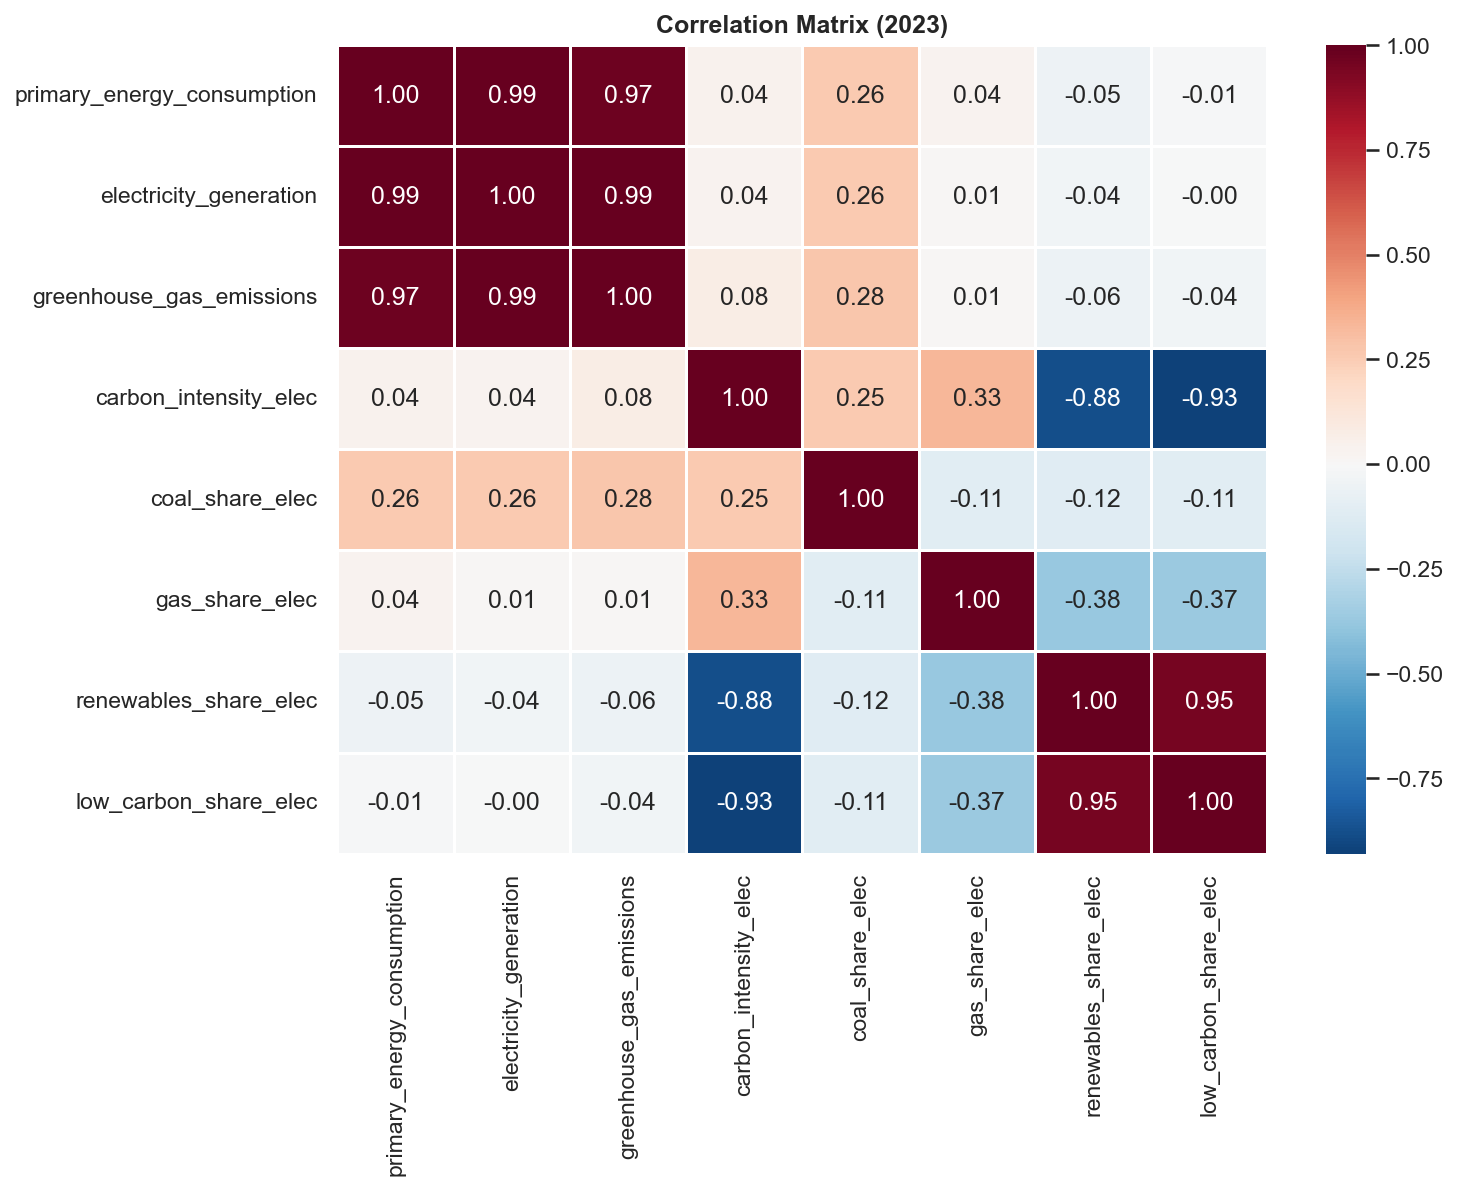

In [30]:
plt.figure(figsize=(10, 7))
corr_cols = [
    'primary_energy_consumption', 'electricity_generation', 'greenhouse_gas_emissions',
    'carbon_intensity_elec', 'coal_share_elec', 'gas_share_elec', 'renewables_share_elec', 'low_carbon_share_elec'
]
sns.heatmap(df_2023[corr_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5)
plt.title("Correlation Matrix (2023)", fontsize=12, fontweight='bold')
plt.savefig("charts/01_correlation_heatmap.png")
plt.show()
plt.close()

## علاقة الطاقة منخفضة الكربون بالكثافة الكربونية

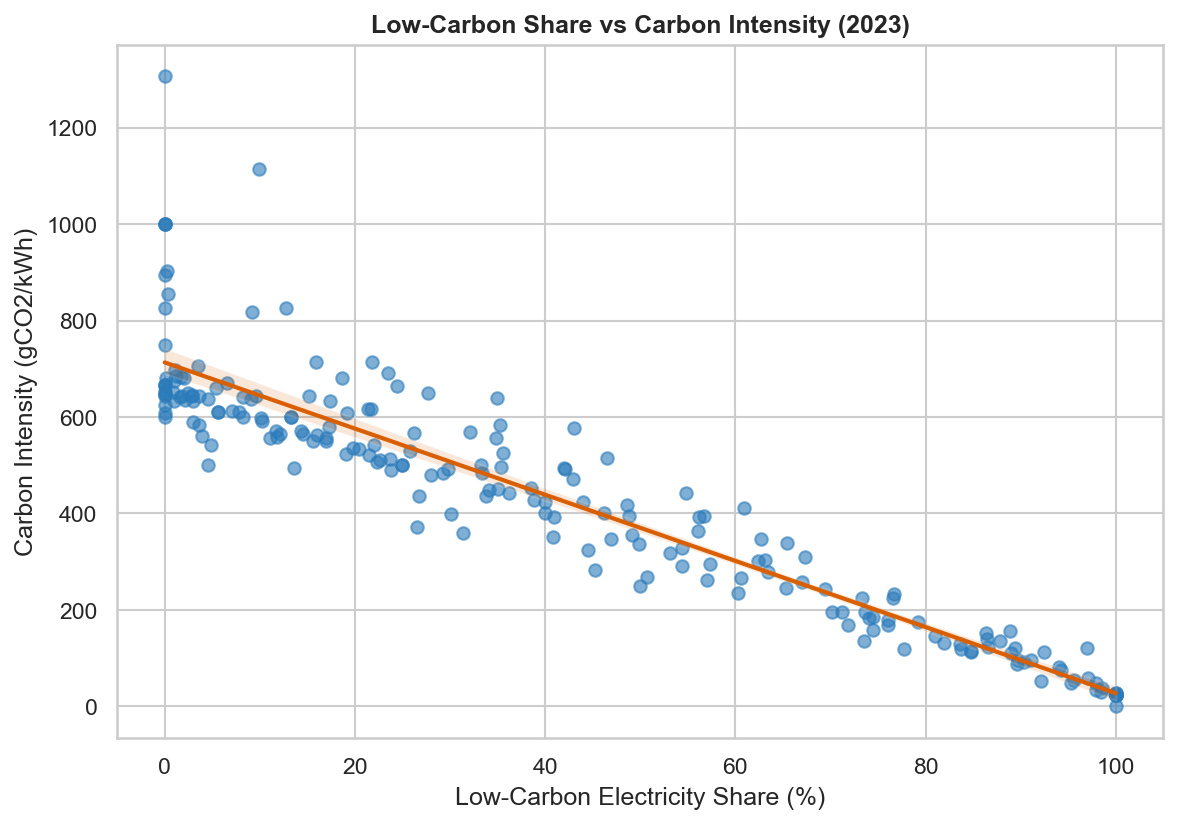

In [31]:
plt.figure(figsize=(9, 6))
sns.regplot(
    data=df_2023, x='low_carbon_share_elec', y='carbon_intensity_elec',
    scatter_kws={'alpha': 0.6, 'color': '#2b7bba'}, line_kws={'color': '#d95f02', 'linewidth': 2}
)
plt.title("Low-Carbon Share vs Carbon Intensity (2023)", fontsize=12, fontweight='bold')
plt.xlabel("Low-Carbon Electricity Share (%)")
plt.ylabel("Carbon Intensity (gCO2/kWh)")
plt.savefig("charts/02_low_carbon_vs_intensity.png")
plt.show()
plt.close()

## توزيع الكثافة الكربونية حسب الفحم

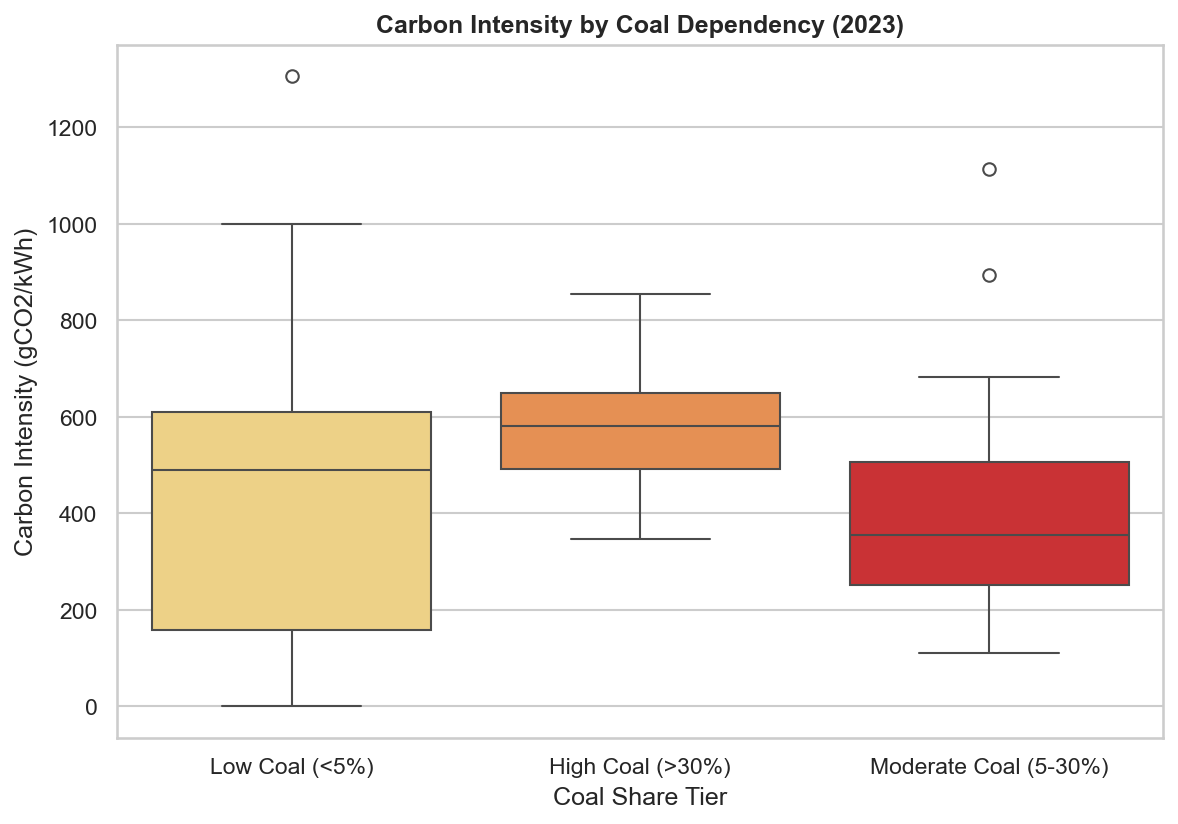

In [32]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=df_2023, x='coal_dependency_group', y='carbon_intensity_elec', palette="YlOrRd")
plt.title("Carbon Intensity by Coal Dependency (2023)", fontsize=12, fontweight='bold')
plt.xlabel("Coal Share Tier")
plt.ylabel("Carbon Intensity (gCO2/kWh)")
plt.savefig("charts/03_coal_dependency_boxplot.png")
plt.show()
plt.close()

## أكبر 5 دول مسببة للانبعاثات

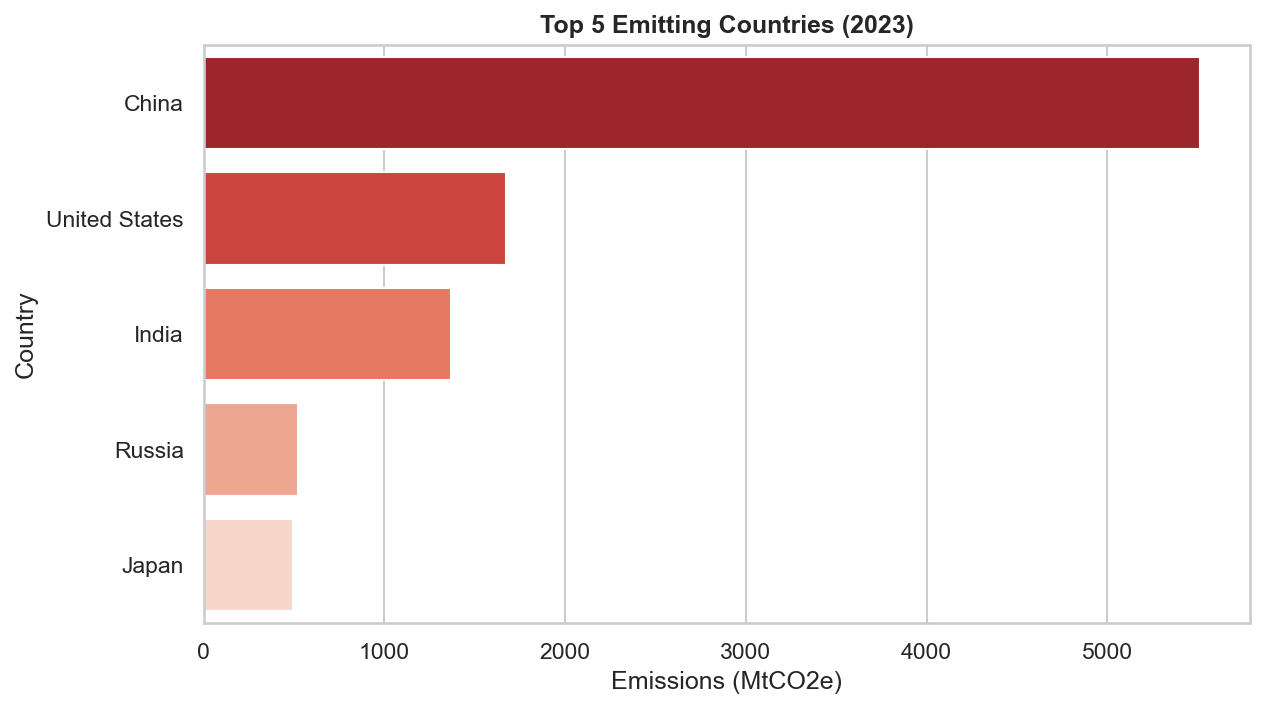

In [33]:
plt.figure(figsize=(9, 5))
sns.barplot(data=top5, x='greenhouse_gas_emissions', y='country', palette="Reds_r")
plt.title("Top 5 Emitting Countries (2023)", fontsize=12, fontweight='bold')
plt.xlabel("Emissions (MtCO2e)")
plt.ylabel("Country")
plt.savefig("charts/04_top5_emitters_2023.png")
plt.show()
plt.close()

## الاتجاه الزمني العالمي للمزيج الكهربائي وحفظ الرسومات

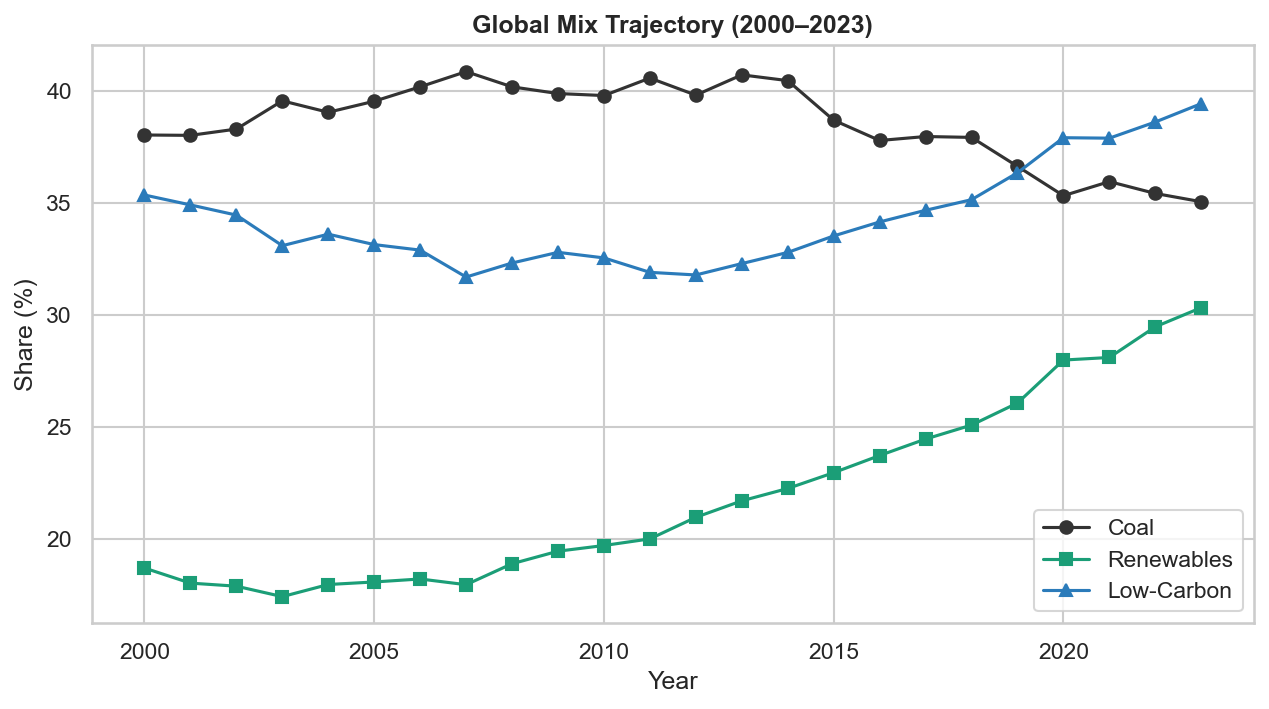

All charts saved successfully in charts/ directory!


In [34]:
world_trend = df_world[df_world['year'].between(2000, 2023)]

plt.figure(figsize=(10, 5))
plt.plot(world_trend['year'], world_trend['coal_share_elec'], label='Coal', marker='o', color='#333333')
plt.plot(world_trend['year'], world_trend['renewables_share_elec'], label='Renewables', marker='s', color='#1b9e77')
plt.plot(world_trend['year'], world_trend['low_carbon_share_elec'], label='Low-Carbon', marker='^', color='#2b7bba')

plt.title("Global Mix Trajectory (2000–2023)", fontsize=12, fontweight='bold')
plt.xlabel("Year")
plt.ylabel("Share (%)")
plt.legend()
plt.savefig("charts/05_global_mix_trend.png")
plt.show()
plt.close()

print("All charts saved successfully in charts/ directory!")